# Credit Card Default – Random Forest
Predicts whether a client defaults next month (UCI *Default of Credit Card Clients*, 30,000 rows).

**Pipeline:** load → clean/encode → stratified split → train Random Forest → tune the decision threshold on a validation set using business cost (a missed defaulter costs 5× a false alarm) → evaluate once on the test set.

## 1. Imports

In [4]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix)

os.makedirs("outputs", exist_ok=True)

def save_csv(df, name, index=False):
    path = f"outputs/{name}.csv"
    df.to_csv(path, index=index)
    print("saved ->", path)

## 2. Load data

In [5]:
df = pd.read_excel("default_of_credit_card_clients.xls", header=1, engine="calamine")
print(df.shape)
df.head()

(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 3. Preprocessing
- Drop `ID`, rename `PAY_0` → `PAY_1` and the target → `DEFAULT`
- `EDUCATION`: undocumented codes 0 and 6 are merged into 5 ("others")
- One-hot encode `EDUCATION` and `MARRIAGE`, map `SEX` to 0/1

In [6]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

df = df.drop(columns=["ID"])
df = df.rename(columns={"PAY_0": "PAY_1", "default payment next month": "DEFAULT"})

for c in ["SEX", "EDUCATION", "MARRIAGE", "DEFAULT"]:
    print(c, df[c].value_counts().sort_index().to_dict())

Missing values: 0
Duplicate rows: 0
SEX {1: 11888, 2: 18112}
EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}
DEFAULT {0: 23364, 1: 6636}


In [7]:
df["EDUCATION"] = df["EDUCATION"].replace({0: 5, 6: 5})

df = pd.get_dummies(df, columns=["EDUCATION", "MARRIAGE"], drop_first=True, dtype=int)
df["SEX"] = df["SEX"].map({1: 0, 2: 1})

df.head()

,LIMIT_BAL,SEX,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,...,PAY_AMT5,PAY_AMT6,DEFAULT,EDUCATION_2,EDUCATION_3,EDUCATION_4,EDUCATION_5,MARRIAGE_1,MARRIAGE_2,MARRIAGE_3
0,20000,1,24,2,2,-1,-1,-2,-2,3913,...,0,0,1,1,0,0,0,1,0,0
1,120000,1,26,-1,2,0,0,0,2,2682,...,0,2000,1,1,0,0,0,0,1,0
2,90000,1,34,0,0,0,0,0,0,29239,...,1000,5000,0,1,0,0,0,0,1,0
3,50000,1,37,0,0,0,0,0,0,46990,...,1069,1000,0,1,0,0,0,1,0,0
4,50000,0,57,-1,0,-1,0,0,0,8617,...,689,679,0,1,0,0,0,1,0,0


## 4. Split
Stratified 80/20 train/test. The training part is split again (80/20) into **fit** (trains the model) and **validation** (picks the threshold), so the test set is never used for tuning.

In [8]:
X = df.drop(columns="DEFAULT")
y = df["DEFAULT"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

print("Fit :", X_fit.shape,  "default rate:", y_fit.mean().round(3))
print("Val :", X_val.shape,  "default rate:", y_val.mean().round(3))
print("Test:", X_test.shape, "default rate:", y_test.mean().round(3))

# no row should appear in more than one set
print("Overlap val/test:", len(X_val.index.intersection(X_test.index)))
print("Overlap val/fit :", len(X_val.index.intersection(X_fit.index)))

Fit : (19200, 28) default rate: 0.221
Val : (4800, 28) default rate: 0.221
Test: (6000, 28) default rate: 0.221
Overlap val/test: 0
Overlap val/fit : 0


## 5. Train the Random Forest
Hyperparameters come from a 12-candidate random search with 3-fold CV, scored on recall (done in the GPU notebook).

In [9]:
best_params = {
    "n_estimators": 150,
    "max_depth": None,
    "max_features": 0.7,
    "min_samples_leaf": 1,
    "min_samples_split": 5,
}

rf = RandomForestClassifier(**best_params, random_state=42, n_jobs=-1)
rf.fit(X_fit, y_fit)

val_probs = rf.predict_proba(X_val)[:, 1]

## 6. Choose the threshold by business cost
Cost = 5 × false negatives (missed defaulters) + 1 × false positives. Sweep thresholds on the validation set and pick the cheapest.

In [10]:
FN_COST, FP_COST = 5, 1

def evaluate_business_cost(y_true, probs, thresholds, fn_cost=FN_COST, fp_cost=FP_COST):
    rows = []
    for t in thresholds:
        pred = (probs >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        rows.append({
            "Threshold": t,
            "Recall": recall_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Total_Cost": fn * fn_cost + fp * fp_cost,
        })
    return pd.DataFrame(rows)

# coarse sweep, then a fine sweep around the best coarse threshold
coarse_df = evaluate_business_cost(y_val, val_probs, np.linspace(0.01, 0.99, 99))
t0 = coarse_df.loc[coarse_df["Total_Cost"].idxmin(), "Threshold"]

fine_df = evaluate_business_cost(y_val, val_probs, np.linspace(max(t0 - 0.05, 0.01), min(t0 + 0.05, 0.99), 400))
best = fine_df.loc[fine_df["Total_Cost"].idxmin()]
best_threshold = float(best["Threshold"])

save_csv(coarse_df.round(4), "rf_01_threshold_sweep_coarse_val")
save_csv(fine_df.round(4),   "rf_02_threshold_sweep_fine_val")

print("Selected threshold:", round(best_threshold, 4))
best.round(4)

saved -> outputs/rf_01_threshold_sweep_coarse_val.csv
saved -> outputs/rf_02_threshold_sweep_fine_val.csv
Selected threshold: 0.1779


Threshold        0.1779
Recall           0.7552
Precision        0.3618
F1               0.4892
TN            2323.0000
FP            1415.0000
FN             260.0000
TP             802.0000
Total_Cost    2715.0000
Name: 271, dtype: float64

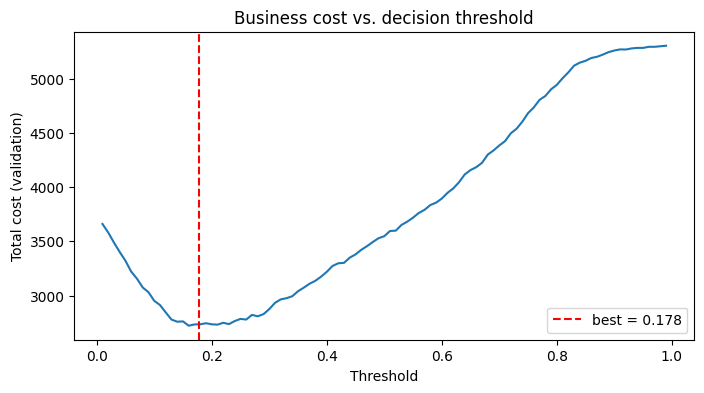

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(coarse_df["Threshold"], coarse_df["Total_Cost"])
plt.axvline(best_threshold, color="red", linestyle="--", label=f"best = {best_threshold:.3f}")
plt.xlabel("Threshold"); plt.ylabel("Total cost (validation)")
plt.title("Business cost vs. decision threshold")
plt.legend(); plt.show()

## 7. Final evaluation on the test set (used once)

In [12]:
test_probs = rf.predict_proba(X_test)[:, 1]
test_pred = (test_probs >= best_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel()

test_metrics = pd.DataFrame([{
    "Threshold": round(best_threshold, 4),
    "Accuracy": accuracy_score(y_test, test_pred),
    "Recall": recall_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred),
    "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    "Test_Cost": fn * FN_COST + fp * FP_COST,
}]).round(4)

save_csv(test_metrics, "rf_03_test_metrics")
test_metrics

saved -> outputs/rf_03_test_metrics.csv


,Threshold,Accuracy,Recall,Precision,F1,TN,FP,FN,TP,Test_Cost
0,0.1779,0.6373,0.7423,0.3494,0.4752,2839,1834,342,985,3544


In [13]:
cm = pd.DataFrame([[tn, fp], [fn, tp]],
                  index=["Actual: no default", "Actual: default"],
                  columns=["Pred: no default", "Pred: default"])
save_csv(cm, "rf_04_confusion_matrix_test", index=True)
cm

saved -> outputs/rf_04_confusion_matrix_test.csv


,Pred: no default,Pred: default
Actual: no default,2839,1834
Actual: default,342,985


## 8. Feature importance

saved -> outputs/rf_05_feature_importance.csv


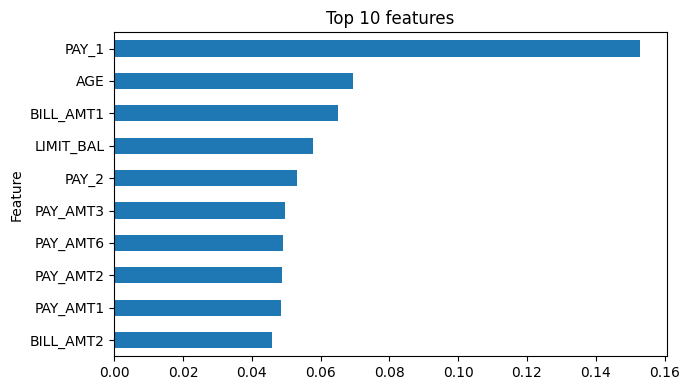

In [ ]:
importance = (pd.DataFrame({"Feature": X.columns, "Importance": rf.feature_importances_})
                .sort_values("Importance", ascending=False)
                .reset_index(drop=True))

save_csv(importance.round(4), "rf_05_feature_importance")

importance.head(10).iloc[::-1].plot.barh(x="Feature", y="Importance", legend=False, figsize=(7, 4))
plt.title("Top 10 features"); plt.tight_layout(); plt.show()

## 9. Save the model

In [15]:
joblib.dump({
    "model": rf,
    "threshold": best_threshold,
    "params": best_params,
    "features": list(X.columns),
    "fn_cost": FN_COST,
    "fp_cost": FP_COST,
}, "random_forest_credit_default.pkl")
print("saved -> random_forest_credit_default.pkl")

saved -> random_forest_credit_default.pkl


In [17]:
X.columns

Index(['LIMIT_BAL', 'SEX', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5',
       'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4',
       'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
       'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'EDUCATION_2', 'EDUCATION_3',
       'EDUCATION_4', 'EDUCATION_5', 'MARRIAGE_1', 'MARRIAGE_2', 'MARRIAGE_3'],
      dtype='str')